# H14. 부품 상태끼리 서로 관련 있게 배치되었는가 (실험 설계)

| 항목 | 내용 |
|---|---|
| 질문 | 한 부품의 상태를 알면 다른 부품의 상태를 짐작할 수 있을까? |
| 귀무가설 H0 | 두 부품의 상태는 서로 독립이다 |
| 대립가설 H1 | 두 부품의 상태는 관련 있다 |
| 검정 | 카이제곱 독립성 검정 (6쌍 → Holm), Cramér's V |
| 출처 (EDA) | F02 상태 조합 교차표, F03 라벨 타임라인 |
| 데이터 | 부품 상태 4개 |
| 왜 중요한가 | 모델이 다른 부품 신호로 답을 짐작하는 지름길 위험 |

**진행 순서:** 1 EDA 시각화 → 2 기술통계 → 3 가정 확인 → 4 정상성 확인 → 5 가설검정(p-값) → 6 사후검정·효과 크기 → 7 블록 평균 재확인 → 8 최종 판정 → 9 해석과 결정

유의수준은 **α = 0.05**로 미리 정했습니다. 표본이 2,205개로 커서 작은 차이도 p < 0.05가 되므로, **결론은 효과 크기와 함께** 내립니다.

In [1]:
from common import *
cyc = load_cycles()
print(cyc.shape)

(2205, 75)


## 1. EDA 시각화

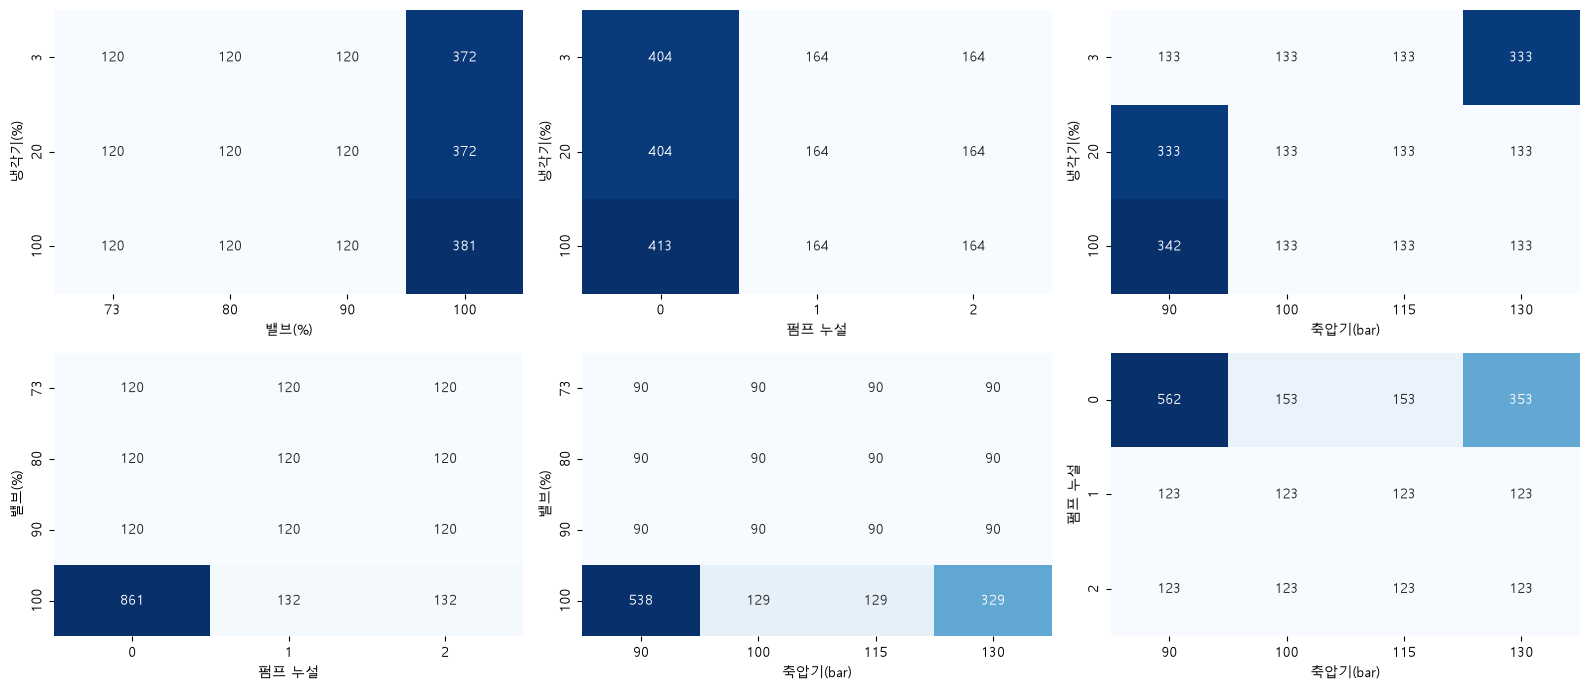

In [2]:
PAIRS = list(itertools.combinations(COMP, 2))
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, (a, b) in zip(axes.ravel(), PAIRS):
    sns.heatmap(pd.crosstab(cyc[a], cyc[b]), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax); ax.set_xlabel(COMP[b]); ax.set_ylabel(COMP[a])
plt.tight_layout(); plt.show()

## 2. 기술통계: 조합 수

In [3]:
print('나올 수 있는 조합 3×4×3×4 =', 3 * 4 * 3 * 4, '/ 실제 등장 조합 =', cyc[list(COMP)].drop_duplicates().shape[0])

나올 수 있는 조합 3×4×3×4 = 144 / 실제 등장 조합 = 144


## 3. 가정 확인 (기대빈도 ≥ 5)

In [4]:
for a, b in PAIRS: print(COMP[a], '×', COMP[b], '최소 기대빈도 =', round(cramers_v(pd.crosstab(cyc[a], cyc[b]))['min_expected'], 1))

냉각기(%) × 밸브(%) 최소 기대빈도 = 119.5
냉각기(%) × 펌프 누설 최소 기대빈도 = 163.3
냉각기(%) × 축압기(bar) 최소 기대빈도 = 132.5
밸브(%) × 펌프 누설 최소 기대빈도 = 80.3
밸브(%) × 축압기(bar) 최소 기대빈도 = 65.1
펌프 누설 × 축압기(bar) 최소 기대빈도 = 89.0


## 4. 정상성 대신: 시간 배치 확인

부품 상태가 바뀌는 주기를 봅니다. 주기가 맞물리면 상태끼리 관련이 생깁니다.

In [5]:
for c in COMP:
    ch = cyc[c].diff().fillna(0) != 0; seglen = cyc.groupby(ch.cumsum()).size()
    print(f"{COMP[c]}: 상태 변경 {ch.sum()}번, 한 상태 유지 길이 중앙값 {seglen.median():.0f} 사이클")

냉각기(%): 상태 변경 2번, 한 상태 유지 길이 중앙값 732 사이클
밸브(%): 상태 변경 144번, 한 상태 유지 길이 중앙값 10 사이클
펌프 누설: 상태 변경 36번, 한 상태 유지 길이 중앙값 41 사이클
축압기(bar): 상태 변경 11번, 한 상태 유지 길이 중앙값 133 사이클


## 5. 가설검정 (p-값)

In [6]:
res = pd.DataFrame([dict(쌍=f"{COMP[a]} × {COMP[b]}", **cramers_v(pd.crosstab(cyc[a], cyc[b]))) for a, b in PAIRS])
res["p_holm"] = holm(res["p"]); res["효과"] = res["V"].map(lambda v: size_label(v, "V"))
display(res.style.format({"chi2": "{:.1f}", "p": "{:.2e}", "p_holm": "{:.2e}", "V": "{:.3f}", "min_expected": "{:.0f}"}))

,쌍,chi2,df,p,V,min_expected,p_holm,효과
0,냉각기(%) × 밸브(%),0.1,6,1.00e+00,0.004,120,1.00e+00,매우 작음
1,냉각기(%) × 펌프 누설,0.1,4,1.00e+00,0.004,163,1.00e+00,매우 작음
2,냉각기(%) × 축압기(bar),237.6,6,1.82e-48,0.232,132,9.09e-48,작음
3,밸브(%) × 펌프 누설,416.1,6,9.45e-87,0.307,80,5.67e-86,중간
4,밸브(%) × 축압기(bar),193.5,9,7.55e-37,0.171,65,3.02e-36,작음
5,펌프 누설 × 축압기(bar),162.5,6,1.79e-32,0.192,89,5.37e-32,작음


## 6. 효과 크기: 한 부품으로 다른 부품을 얼마나 맞힐 수 있나

밸브 상태만 보고 펌프 상태를 "가장 흔한 값"으로 찍었을 때의 정확도를, 아무 정보 없이 찍었을 때와 비교합니다.

In [7]:
def guess_acc(a, b):
    mode = cyc.groupby(a)[b].agg(lambda s: s.value_counts().idxmax()); return (cyc[a].map(mode) == cyc[b]).mean()
rows = [dict(보는_부품=COMP[a], 맞히는_부품=COMP[b], 정보없이=cyc[b].value_counts(normalize=True).max(), 보고서=guess_acc(a, b)) for a, b in PAIRS] + \
       [dict(보는_부품=COMP[b], 맞히는_부품=COMP[a], 정보없이=cyc[a].value_counts(normalize=True).max(), 보고서=guess_acc(b, a)) for a, b in PAIRS]
g = pd.DataFrame(rows); g["향상"] = g["보고서"] - g["정보없이"]; display(g.sort_values("향상", ascending=False).round(3))

,보는_부품,맞히는_부품,정보없이,보고서,향상
8,축압기(bar),냉각기(%),0.336,0.427,0.091
2,냉각기(%),축압기(bar),0.366,0.457,0.091
1,냉각기(%),펌프 누설,0.554,0.554,0.000
0,냉각기(%),밸브(%),0.510,0.510,0.000
3,밸브(%),펌프 누설,0.554,0.554,0.000
4,밸브(%),축압기(bar),0.366,0.366,0.000
6,밸브(%),냉각기(%),0.336,0.336,0.000
5,펌프 누설,축압기(bar),0.366,0.366,0.000
7,펌프 누설,냉각기(%),0.336,0.336,0.000
9,펌프 누설,밸브(%),0.510,0.510,0.000


## 7. 재확인: 안정 사이클만

In [8]:
st0 = cyc[cyc.stable_flag == 0]
display(pd.DataFrame([dict(쌍=f"{COMP[a]} × {COMP[b]}", V_안정만=cramers_v(pd.crosstab(st0[a], st0[b]))["V"]) for a, b in PAIRS]).round(3))

,쌍,V_안정만
0,냉각기(%) × 밸브(%),0.011
1,냉각기(%) × 펌프 누설,0.009
2,냉각기(%) × 축압기(bar),0.011
3,밸브(%) × 펌프 누설,0.011
4,밸브(%) × 축압기(bar),0.011
5,펌프 누설 × 축압기(bar),0.011


## 8. 최종 판정

In [9]:
final = res[["쌍", "chi2", "df", "p_holm", "V"]].copy(); final["판정"] = np.where(final.p_holm < ALPHA, "H0 기각", "H0 유지")
display(final.style.format({"chi2": "{:.1f}", "p_holm": "{:.2e}", "V": "{:.3f}"}))
sig = final[final.판정 == "H0 기각"]
save_result("H14", title="부품 상태 조합 독립성", test="카이제곱 (6쌍, Holm)", stat=f"{len(sig)}/6쌍 유의", p=float(sig.p_holm.max()) if len(sig) else float(final.p_holm.min()),
            effect=f"V = {sig.V.min():.2f}~{sig.V.max():.2f}" if len(sig) else "-", verdict=f"{len(sig)}쌍 H0 기각")

,쌍,chi2,df,p_holm,V,판정
0,냉각기(%) × 밸브(%),0.1,6,1.00e+00,0.004,H0 유지
1,냉각기(%) × 펌프 누설,0.1,4,1.00e+00,0.004,H0 유지
2,냉각기(%) × 축압기(bar),237.6,6,9.09e-48,0.232,H0 기각
3,밸브(%) × 펌프 누설,416.1,6,5.67e-86,0.307,H0 기각
4,밸브(%) × 축압기(bar),193.5,9,3.02e-36,0.171,H0 기각
5,펌프 누설 × 축압기(bar),162.5,6,5.37e-32,0.192,H0 기각


저장: results/H14.json


## 9. 해석과 결정

- 냉각기는 밸브·펌프와 완전히 독립입니다(V ≈ 0). 나머지 4쌍은 통계적으로 관련이 있지만 효과는 약~중간입니다(V ≈ 0.17~0.31).
- 6단계에서 "한 부품의 가장 흔한 상태로 다른 부품 찍기"를 해 보면, 맞히는 비율이 오르는 것은 **냉각기 ↔ 축압기(+9%p)뿐**입니다. 다른 쌍은 분포가 조금 다를 뿐, 가장 흔한 상태는 같아서 짐작에 도움이 안 됩니다.
- **결정:** 지름길 위험이 가장 큰 곳은 **냉각기 ↔ 축압기**입니다. SOA에서 축압기 모델이 냉각기 신호로 답을 찍는지 점검했고, 그런 지름길은 발견되지 않았습니다. 밸브·펌프 모델은 판단 근거(특징 중요도)에 다른 부품의 센서가 상위로 나오는지만 확인하면 됩니다(4.1.2).